In [ ]:
import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
from scipy import signal
from scipy.optimize import curve_fit
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
os.makedirs('/content/fig', exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 8.0,
    'legend.frameon': True,
    'legend.facecolor': 'white',
    'legend.framealpha': 0.85,
    'legend.edgecolor': '#cccccc',
    'axes.linewidth': 0.8,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'savefig.bbox': 'tight',
    'figure.dpi': 150
})

# Paleta Okabe-Ito
OI_BLUE   = '#0072B2'
OI_ORANGE = '#D55E00'
OI_GREEN  = '#009E73'
OI_PINK   = '#CC79A7'
OI_CYAN   = '#56B4E9'
OI_YELLOW = '#E69F00'
OI_BLACK  = '#111111'

# 1. Intentar montar Drive si no está montado
if not os.path.exists('/content/drive/MyDrive'):
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception:
        pass

# 2. Verificar si existen archivos WAV de D1 y D2; si faltan, pedir subida
wavs_encontrados = glob.glob('/content/**/*.wav', recursive=True)
if len(wavs_encontrados) < 4:
    try:
        from google.colab import files
        print("📂 No se encontraron todos los archivos .wav en /content ni en Drive.")
        print("👉 Selecciona tus archivos WAV (los 4 de D1 y los 12 de D2) y los CSV si los tienes:")
        files.upload()
        wavs_encontrados = glob.glob('/content/**/*.wav', recursive=True)
    except Exception:
        pass

def buscar_archivos(patron):
    return sorted(glob.glob(f'/content/**/{patron}', recursive=True))

def disenar_filtro_sos(f_central, bw=20.0, fs=44100, orden=2):
    nyq = 0.5 * fs
    low = max((f_central - bw / 2.0) / nyq, 0.001)
    high = min((f_central + bw / 2.0) / nyq, 0.999)
    return signal.butter(orden, [low, high], btype='bandpass', output='sos')

print(f"✅ Entorno listo. Archivos WAV detectados: {len(wavs_encontrados)}")

✅ Entorno listo. Archivos WAV detectados: 4


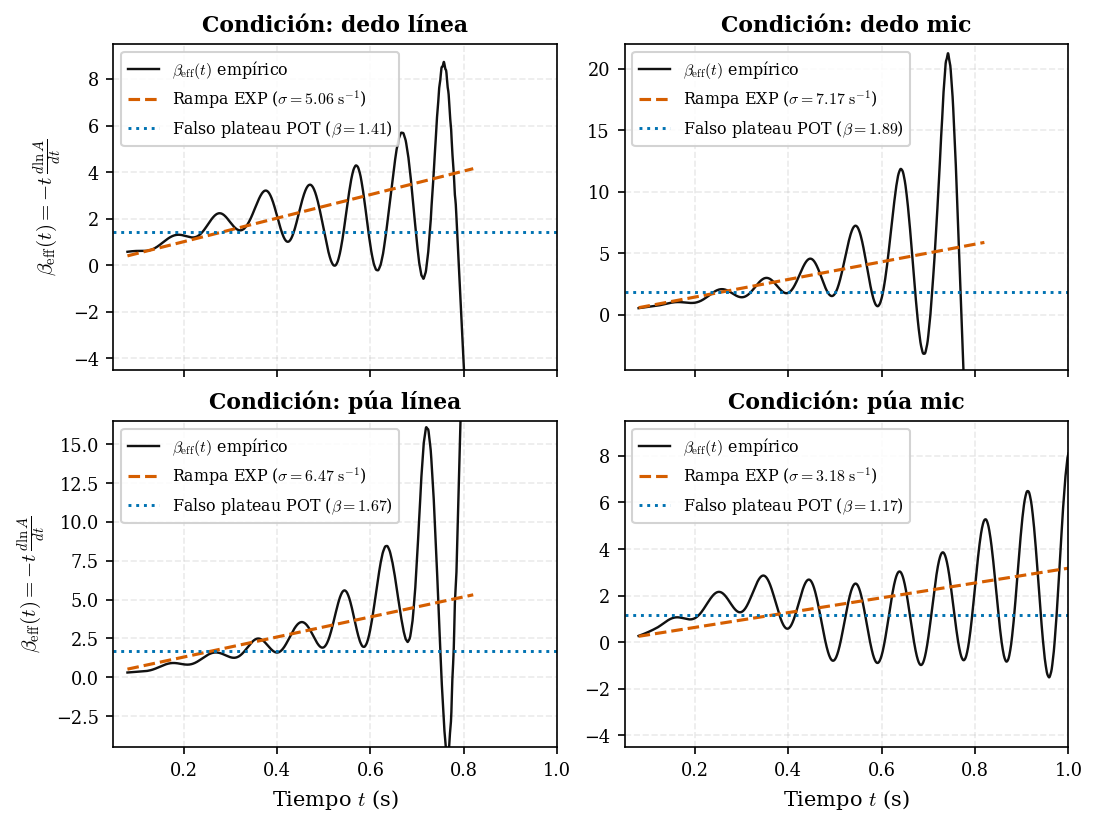

✅ [A1] Limpia guardada: /content/fig/Fig_6_2_Embudo_Batido_beta_eff.pdf


In [ ]:
condiciones_d1 = [
    ('*dedo*linea*.wav', 'Condición: dedo línea', 5.06, 1.41, 9.5),
    ('*dedo*mic*.wav',   'Condición: dedo mic',   7.17, 1.89, 22.0),
    ('*pua*linea*.wav',  'Condición: púa línea',  6.47, 1.67, 16.5),
    ('*pua*mi*c*.wav',   'Condición: púa mic',    3.18, 1.17, 9.5)
]

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True, constrained_layout=True)
axes = axes.flatten()

for idx, (pat, titulo, sig_temprana, beta_pot, y_max) in enumerate(condiciones_d1):
    ax = axes[idx]
    rutas = buscar_archivos(pat)
    if not rutas:
        raise FileNotFoundError(f"Falta archivo D1: {pat}")

    y, sr = librosa.load(rutas[0], sr=None, mono=True)
    y_filt = signal.sosfiltfilt(disenar_filtro_sos(196.0, 20.0, sr), y)
    ruido_rms = np.sqrt(np.mean(y_filt[:int(0.5 * sr)]**2)) + 1e-12

    win = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win)/win, mode='same'))
    picos, props = signal.find_peaks(rms_env, distance=int(3.5 * sr), prominence=np.max(rms_env)*0.02)
    if len(picos) > 5:
        picos = np.sort(picos[np.argsort(props['prominences'])[::-1][:5]])

    pk = picos[0]
    ini = pk + int(0.05 * sr)
    lim = min(picos[1] - int(0.2 * sr), ini + int(2.5 * sr))
    umb = max(3.0 * ruido_rms, 0.015 * rms_env[pk])
    deb = np.where(rms_env[ini:lim] < umb)[0]
    fin = ini + max(deb[0], int(0.80 * sr)) if len(deb) > 0 else ini + int(0.85 * sr)

    env = np.abs(signal.hilbert(y_filt[ini:fin]))
    cut = int(0.03 * sr)
    A = env[cut:-cut]
    t = np.arange(len(A)) / sr + 0.08

    win_sg = int(0.07 * sr) | 1
    beta_eff = -t * signal.savgol_filter(np.log(A + 1e-12), win_sg, 2, deriv=1, delta=1.0/sr)

    ax.plot(t, beta_eff, color=OI_BLACK, lw=1.15, label=r'$\beta_{\mathrm{eff}}(t)$ empírico')
    ax.plot(t, sig_temprana * t, color=OI_ORANGE, ls='--', lw=1.5,
            label=rf'Rampa EXP ($\sigma={sig_temprana:.2f}\ \mathrm{{s}}^{{-1}}$)')
    ax.axhline(beta_pot, color=OI_BLUE, ls=':', lw=1.4,
               label=rf'Falso plateau POT ($\beta={beta_pot:.2f}$)')
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlim(0.05, 1.0)
    ax.set_ylim(-4.5, y_max)
    if idx % 2 == 0:
        ax.set_ylabel(r'$\beta_{\mathrm{eff}}(t) = -t\,\frac{d\ln A}{dt}$')
    if idx >= 2:
        ax.set_xlabel('Tiempo $t$ (s)')
    ax.legend(loc='upper left', fontsize=7.6)

plt.savefig('/content/fig/Fig_6_2_Embudo_Batido_beta_eff.pdf')
plt.savefig('/content/fig/Fig_6_2_Embudo_Batido_beta_eff_preview.png', dpi=300)
plt.show()
print("✅ [A1] Limpia guardada: /content/fig/Fig_6_2_Embudo_Batido_beta_eff.pdf")

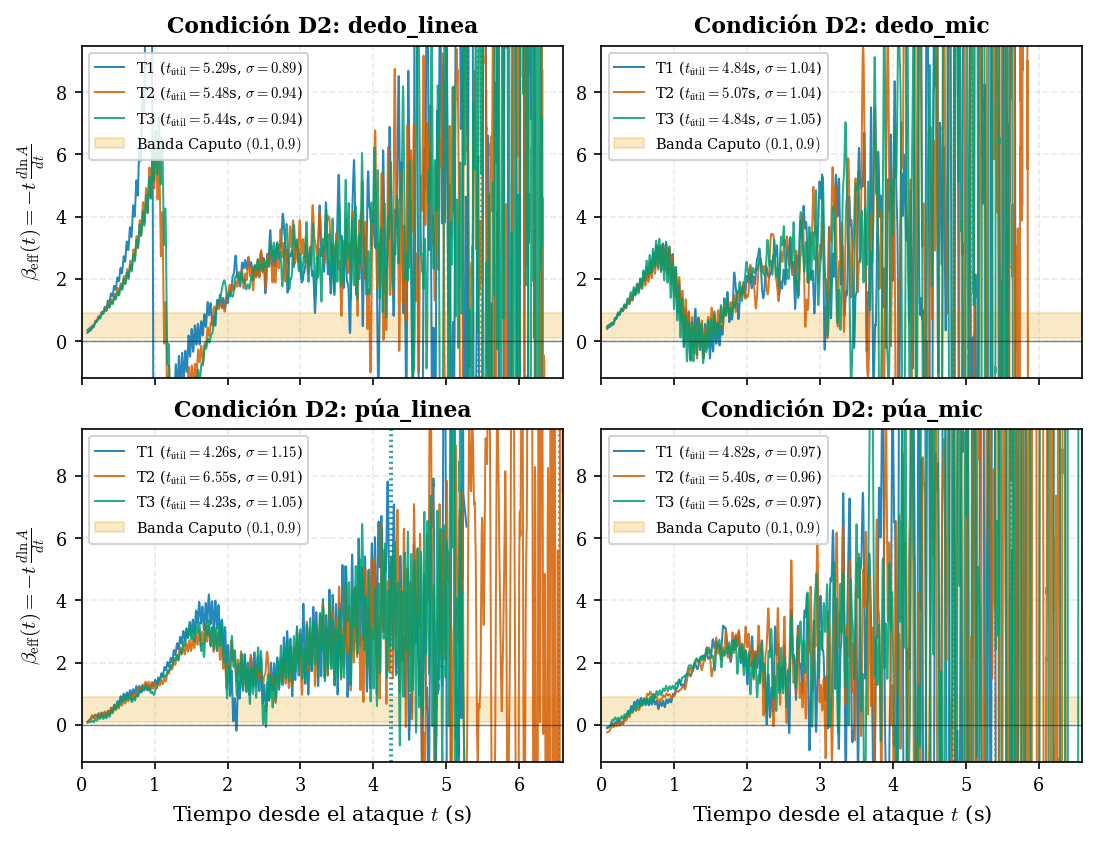

✅ [A2] Limpia guardada: /content/fig/Fig_D2_beta_eff_Ventana_Extendida.pdf


In [ ]:
conds_d2 = [
    ('*Jack*dedo*.wav', 'Condición D2: dedo_linea'),
    ('*XLR*dedo*.wav',  'Condición D2: dedo_mic'),
    ('*Jack*pua*.wav',  'Condición D2: púa_linea'),
    ('*XLR*pua*.wav',   'Condición D2: púa_mic')
]
colores_tomas = [OI_BLUE, OI_ORANGE, OI_GREEN]

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.5), sharex=True, constrained_layout=True)
axes = axes.flatten()

for idx, (pat, titulo) in enumerate(conds_d2):
    ax = axes[idx]
    archivos = buscar_archivos(pat)
    if len(archivos) < 3:
        raise FileNotFoundError(f"Faltan archivos D2 para {pat} (encontrados: {len(archivos)})")

    for r_i, ruta in enumerate(archivos[:3]):
        y, sr = librosa.load(ruta, sr=None, mono=True)
        y_filt = signal.sosfiltfilt(disenar_filtro_sos(196.0, 20.0, sr), y)
        win = int(0.02 * sr)
        rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win)/win, mode='same'))
        pk = int(np.argmax(rms_env))

        pre_ini, pre_fin = int(0.10 * sr), max(int(0.25 * sr), pk - int(0.15 * sr))
        ruido_pre = np.sqrt(np.mean(y_filt[pre_ini:pre_fin]**2)) + 1e-12

        ini = pk + int(0.05 * sr)
        lim = len(y_filt) - int(0.05 * sr)
        cruce = np.where(rms_env[ini:lim] < 2.5 * ruido_pre)[0]
        fin_util = ini + cruce[0] if len(cruce) > 0 else lim
        fin_ext = min(fin_util + int(1.0 * sr), lim)

        dur_util = (fin_util - ini) / sr
        env = np.abs(signal.hilbert(y_filt[ini:fin_ext]))
        cut = int(0.03 * sr)
        A = env[cut:-cut]
        t = np.arange(len(A)) / sr + 0.08

        n_u = min(max(int((dur_util - 0.06) * sr), int(0.3 * sr)), len(A))
        sig_u = max(-np.polyfit(t[:n_u], np.log(A[:n_u] + 1e-12), 1)[0], 0.1)

        win_sg = min(int(0.09 * sr) | 1, len(A) - 2)
        beta_eff = -t * signal.savgol_filter(np.log(A + 1e-12), win_sg, 2, deriv=1, delta=1.0/sr)

        ax.plot(t, beta_eff, color=colores_tomas[r_i], lw=0.95, alpha=0.85,
                label=rf'T{r_i+1} ($t_{{\mathrm{{útil}}}}={dur_util:.2f}$s, $\sigma={sig_u:.2f}$)')
        ax.axvline(dur_util, color=colores_tomas[r_i], ls=':', lw=1.0, alpha=0.8)

    ax.axhspan(0.1, 0.9, color=OI_YELLOW, alpha=0.22, label=r'Banda Caputo $(0.1,0.9)$')
    ax.axhline(0, color=OI_BLACK, lw=0.7, alpha=0.5)
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylim(-1.2, 9.5)
    ax.set_xlim(0.0, 6.6)
    if idx % 2 == 0:
        ax.set_ylabel(r'$\beta_{\mathrm{eff}}(t) = -t\,\frac{d\ln A}{dt}$')
    if idx >= 2:
        ax.set_xlabel('Tiempo desde el ataque $t$ (s)')
    ax.legend(loc='upper left', fontsize=7.0, ncol=1)

plt.savefig('/content/fig/Fig_D2_beta_eff_Ventana_Extendida.pdf')
plt.savefig('/content/fig/Fig_D2_beta_eff_Ventana_Extendida_preview.png', dpi=300)
plt.show()
print("✅ [A2] Limpia guardada: /content/fig/Fig_D2_beta_eff_Ventana_Extendida.pdf")

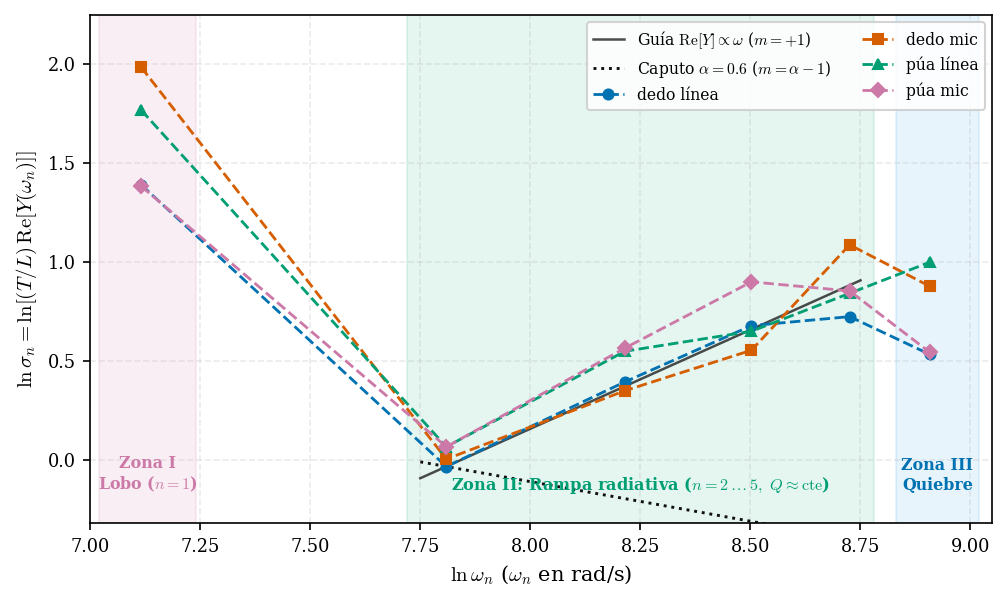

✅ [A3] Limpia guardada: /content/fig/Fig_6_1_Espectroscopia_Admitancia_Puente.pdf


In [ ]:
T_L = 92.0
n_modos = np.arange(1, 7)
w_n = 2 * np.pi * 196.0 * n_modos
ln_w = np.log(w_n)

ReY_mat = np.array([
    [0.0436, 0.0790, 0.0636, 0.0433],
    [0.0105, 0.0109, 0.0116, 0.0116],
    [0.0161, 0.0154, 0.0188, 0.0191],
    [0.0214, 0.0189, 0.0208, 0.0267],
    [0.0224, 0.0322, 0.0252, 0.0255],
    [0.0185, 0.0261, 0.0295, 0.0187]
])
sigma_mat = T_L * ReY_mat

csvs_r1 = buscar_archivos('ruta_R1_resultados_limpios.csv')
iqr_mat = np.zeros_like(sigma_mat)
if csvs_r1:
    df_r1 = pd.read_csv(csvs_r1[0])
    cond_keys = [('dedo', 'lin'), ('dedo', 'mic'), ('pua', 'lin'), ('pua', 'mic')]
    for c_i, (k1, k2) in enumerate(cond_keys):
        sub = df_r1[df_r1['condicion'].str.contains(k1) & df_r1['condicion'].str.contains(k2)]
        if not sub.empty and 'sigma_n' in sub.columns:
            for m_i, n_val in enumerate(n_modos):
                vals = sub[sub['armonico'] == n_val]['sigma_n']
                if len(vals) > 0:
                    iqr_mat[m_i, c_i] = np.percentile(vals, 75) - np.percentile(vals, 25)

fig, ax = plt.subplots(figsize=(6.6, 3.9), constrained_layout=True)

ax.axvspan(7.02, 7.24, color=OI_PINK, alpha=0.12)
ax.axvspan(7.72, 8.78, color=OI_GREEN, alpha=0.10)
ax.axvspan(8.83, 9.02, color=OI_CYAN, alpha=0.14)

ax.text(7.13, -0.15, 'Zona I\nLobo ($n=1$)', ha='center', fontsize=7.6, color=OI_PINK, fontweight='bold')
ax.text(8.25, -0.15, r'Zona II: Rampa radiativa ($n=2\dots 5,\ Q \approx \mathrm{cte}$)',
        ha='center', fontsize=7.8, color=OI_GREEN, fontweight='bold')
ax.text(8.925, -0.15, 'Zona III\nQuiebre', ha='center', fontsize=7.6, color=OI_BLUE, fontweight='bold')

etiquetas_c = ['dedo línea', 'dedo mic', 'púa línea', 'púa mic']
colores_c = [OI_BLUE, OI_ORANGE, OI_GREEN, OI_PINK]
marcadores_c = ['o', 's', '^', 'D']

for c_i in range(4):
    ln_sig = np.log(sigma_mat[:, c_i])
    yerr_ln = (0.5 * iqr_mat[:, c_i]) / sigma_mat[:, c_i] if np.any(iqr_mat) else None
    ax.errorbar(ln_w, ln_sig, yerr=yerr_ln, fmt=marcadores_c[c_i] + '--', color=colores_c[c_i],
                lw=1.35, markersize=4.8, capsize=2.5, label=etiquetas_c[c_i])

ln_w_banda = np.linspace(7.75, 8.75, 50)
guia_mas1 = (ln_w_banda - ln_w[1]) * 1.0 + np.log(sigma_mat[1, 0])
guia_caputo = (ln_w_banda - ln_w[1]) * (-0.40) + np.log(sigma_mat[1, 0])

ax.plot(ln_w_banda, guia_mas1, color=OI_BLACK, ls='-', lw=1.2, alpha=0.75, label=r'Guía $\mathrm{Re}[Y]\propto\omega$ ($m=+1$)')
ax.plot(ln_w_banda, guia_caputo, color=OI_BLACK, ls=':', lw=1.4, label=r'Caputo $\alpha=0.6$ ($m=\alpha-1$)')

ax.set_xlabel(r'$\ln \omega_n$ ($\omega_n$ en rad/s)')
ax.set_ylabel(r'$\ln \sigma_n = \ln[(T/L)\,\mathrm{Re}[Y(\omega_n)]]$')
ax.set_xlim(7.00, 9.05)
ax.set_ylim(-0.32, 2.25)
ax.legend(loc='upper right', ncol=2, fontsize=7.5)

plt.savefig('/content/fig/Fig_6_1_Espectroscopia_Admitancia_Puente.pdf')
plt.savefig('/content/fig/Fig_6_1_Espectroscopia_Admitancia_Puente_preview.png', dpi=300)
plt.show()
print("✅ [A3] Limpia guardada: /content/fig/Fig_6_1_Espectroscopia_Admitancia_Puente.pdf")

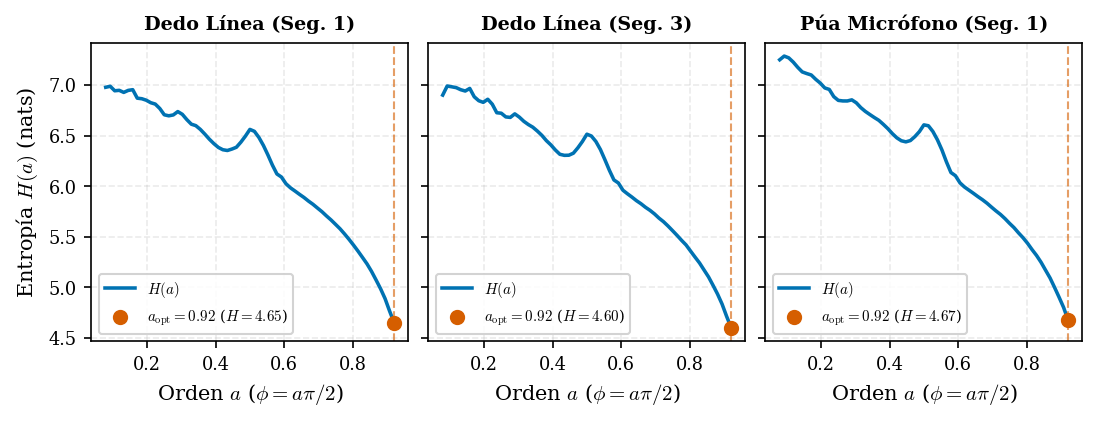

✅ [A4] Limpia guardada: /content/fig/Fig_FrFT_Validacion_Cruzada.pdf


In [ ]:
def frft_suave(x, a):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    if np.isclose(a, 0.0): return x
    if np.isclose(a, 1.0): return np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x))) / np.sqrt(N)
    phi = a * np.pi / 2.0
    cot_phi, csc_phi = 1.0 / np.tan(phi), 1.0 / np.sin(phi)
    t = (np.arange(N) - N / 2.0) / np.sqrt(N)
    chirp1 = np.exp(1j * np.pi * cot_phi * (t**2))
    chirp_conv = np.exp(-1j * np.pi * csc_phi * (t**2))
    tau = (np.arange(-(N - 1), N)) / np.sqrt(N)
    kernel = np.exp(1j * np.pi * csc_phi * (tau**2))
    conv_res = signal.fftconvolve((x * chirp1) * chirp_conv, kernel, mode='same')
    norm = np.sqrt(abs(csc_phi) / N) * np.exp(-1j * (np.pi / 4.0 - phi / 2.0))
    return norm * chirp1 * chirp_conv * conv_res

casos_frft = [
    ('*dedo*linea*.wav', 0, 'Dedo Línea (Seg. 1)'),
    ('*dedo*linea*.wav', 2, 'Dedo Línea (Seg. 3)'),
    ('*pua*mi*c*.wav',   0, 'Púa Micrófono (Seg. 1)')
]

a_vals = np.linspace(0.08, 0.92, 65)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.7), sharey=True, constrained_layout=True)

for idx, (pat, seg_id, titulo) in enumerate(casos_frft):
    rutas = buscar_archivos(pat)
    y, sr = librosa.load(rutas[0], sr=None, mono=True)
    y_filt = signal.sosfiltfilt(disenar_filtro_sos(196.0, 20.0, sr), y)
    ruido_rms = np.sqrt(np.mean(y_filt[:int(0.5 * sr)]**2)) + 1e-12

    win = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win)/win, mode='same'))
    picos, props = signal.find_peaks(rms_env, distance=int(3.5 * sr), prominence=np.max(rms_env)*0.02)
    if len(picos) > 5:
        picos = np.sort(picos[np.argsort(props['prominences'])[::-1][:5]])

    pk = picos[seg_id]
    ini = pk + int(0.05 * sr)
    lim = min(picos[seg_id + 1] - int(0.2 * sr) if seg_id < len(picos)-1 else len(y_filt)-1, ini + int(2.5 * sr))
    umb = max(3.0 * ruido_rms, 0.015 * rms_env[pk])
    deb = np.where(rms_env[ini:lim] < umb)[0]
    fin = ini + max(deb[0], int(0.80 * sr)) if len(deb) > 0 else ini + int(0.85 * sr)

    A = np.abs(signal.hilbert(y_filt[ini:fin]))
    cut = int(0.03 * sr)
    A_dec = signal.decimate(A[cut:-cut], max(1, int(round(sr / 2000.0))))
    A_norm = (A_dec - np.mean(A_dec)) / (np.std(A_dec) + 1e-12)

    H_arr = np.zeros(len(a_vals))
    for i_a, a in enumerate(a_vals):
        P_u = np.abs(frft_suave(A_norm, a))**2
        P_u /= (np.sum(P_u) + 1e-12)
        H_arr[i_a] = -np.sum(P_u * np.log(P_u + 1e-12))

    i_min = np.argmin(H_arr)
    a_opt, H_min = a_vals[i_min], H_arr[i_min]

    ax = axes[idx]
    ax.plot(a_vals, H_arr, color=OI_BLUE, lw=1.7, label=r'$H(a)$')
    ax.scatter([a_opt], [H_min], color=OI_ORANGE, s=40, zorder=5,
               label=rf'$a_{{\mathrm{{opt}}}}={a_opt:.2f}$ ($H={H_min:.2f}$)')
    ax.axvline(a_opt, color=OI_ORANGE, ls='--', lw=1.0, alpha=0.6)
    ax.set_title(titulo, fontsize=9.2, fontweight='bold')
    ax.set_xlabel(r'Orden $a$ ($\phi=a\pi/2$)')
    if idx == 0:
        ax.set_ylabel(r'Entropía $H(a)$ (nats)')
    ax.legend(loc='lower left', fontsize=7.2)

plt.savefig('/content/fig/Fig_FrFT_Validacion_Cruzada.pdf')
plt.savefig('/content/fig/Fig_FrFT_Validacion_Cruzada_preview.png', dpi=300)
plt.show()
print("✅ [A4] Limpia guardada: /content/fig/Fig_FrFT_Validacion_Cruzada.pdf")

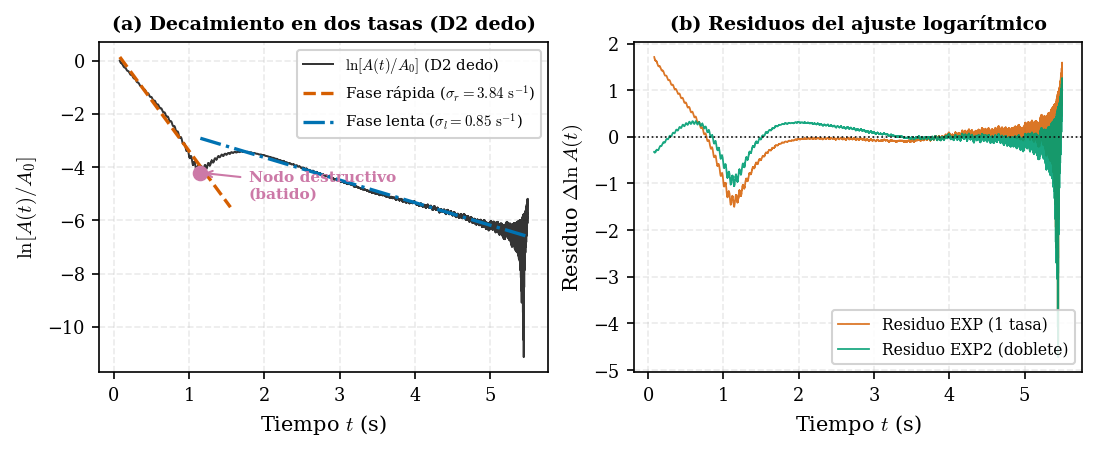

✅ [A5] Nueva guardada: /content/fig/Fig_6_5_Dos_Tasas.pdf (σ_r=3.84 s⁻¹, σ_l=0.85 s⁻¹)


In [ ]:
rutas_dedo_d2 = buscar_archivos('*Jack*dedo*003*.wav') or buscar_archivos('*Jack*dedo*.wav')
y, sr = librosa.load(rutas_dedo_d2[0], sr=None, mono=True)
y_filt = signal.sosfiltfilt(disenar_filtro_sos(196.0, 20.0, sr), y)

win = int(0.02 * sr)
rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win)/win, mode='same'))
pk = int(np.argmax(rms_env))
pre_ini, pre_fin = int(0.10 * sr), max(int(0.25 * sr), pk - int(0.15 * sr))
ruido_pre = np.sqrt(np.mean(y_filt[pre_ini:pre_fin]**2)) + 1e-12

ini = pk + int(0.05 * sr)
cruce = np.where(rms_env[ini:] < 2.5 * ruido_pre)[0]
fin_util = ini + cruce[0] if len(cruce) > 0 else len(y_filt) - int(0.05 * sr)

env = np.abs(signal.hilbert(y_filt[ini:fin_util]))
cut = int(0.03 * sr)
A = env[cut:-cut]
t = np.arange(len(A)) / sr + 0.08
ln_A = np.log(A / A[0] + 1e-12)

m_rap = t <= 1.15
m_len = t >= 1.60
p_rap = np.polyfit(t[m_rap], ln_A[m_rap], 1)
p_len = np.polyfit(t[m_len], ln_A[m_len], 1)
sig_rap, sig_len = -p_rap[0], -p_len[0]

p_exp1 = np.polyfit(t, ln_A, 1)
ln_exp1 = np.polyval(p_exp1, t)

def modelo_exp2(t_arr, a1, s1, a2, s2):
    return np.log(np.maximum(a1 * np.exp(-s1 * t_arr) + a2 * np.exp(-s2 * t_arr), 1e-12))

popt, _ = curve_fit(modelo_exp2, t[::10], ln_A[::10],
                    p0=[0.85, 3.4, 0.15, 0.95], bounds=([0, 1.5, 0, 0.2], [2, 8.0, 1, 2.0]), maxfev=5000)
ln_exp2 = modelo_exp2(t, *popt)

idx_nodo = np.where((t >= 1.0) & (t <= 1.6))[0]
t_nodo = t[idx_nodo[np.argmin(ln_A[idx_nodo])]]
y_nodo = np.min(ln_A[idx_nodo])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.9), constrained_layout=True)

ax1.plot(t, ln_A, color=OI_BLACK, lw=0.95, alpha=0.85, label=r'$\ln[A(t)/A_0]$ (D2 dedo)')
ax1.plot(t[t <= 1.55], np.polyval(p_rap, t[t <= 1.55]), color=OI_ORANGE, ls='--', lw=1.6,
         label=rf'Fase rápida ($\sigma_r = {sig_rap:.2f}\ \mathrm{{s}}^{{-1}}$)')
ax1.plot(t[t >= 1.15], np.polyval(p_len, t[t >= 1.15]), color=OI_BLUE, ls='-.', lw=1.6,
         label=rf'Fase lenta ($\sigma_l = {sig_len:.2f}\ \mathrm{{s}}^{{-1}}$)')
ax1.scatter([t_nodo], [y_nodo], color=OI_PINK, s=42, zorder=5)
ax1.annotate('Nodo destructivo\n(batido)', xy=(t_nodo, y_nodo), xytext=(t_nodo + 0.65, y_nodo - 0.95),
             arrowprops=dict(arrowstyle='->', color=OI_PINK, lw=1.0), fontsize=7.4, fontweight='bold', color=OI_PINK)
ax1.set_title('(a) Decaimiento en dos tasas (D2 dedo)', fontsize=9.2, fontweight='bold')
ax1.set_xlabel('Tiempo $t$ (s)')
ax1.set_ylabel(r'$\ln[A(t)/A_0]$')
ax1.legend(loc='upper right', fontsize=7.2)

ax2.plot(t, ln_A - ln_exp1, color=OI_ORANGE, lw=0.85, alpha=0.85, label='Residuo EXP (1 tasa)')
ax2.plot(t, ln_A - ln_exp2, color=OI_GREEN, lw=0.85, alpha=0.9, label='Residuo EXP2 (doblete)')
ax2.axhline(0, color=OI_BLACK, lw=0.8, ls=':')
ax2.set_title('(b) Residuos del ajuste logarítmico', fontsize=9.2, fontweight='bold')
ax2.set_xlabel('Tiempo $t$ (s)')
ax2.set_ylabel(r'Residuo $\Delta \ln A(t)$')
ax2.legend(loc='lower right', fontsize=7.5)

plt.savefig('/content/fig/Fig_6_5_Dos_Tasas.pdf')
plt.savefig('/content/fig/Fig_6_5_Dos_Tasas_preview.png', dpi=300)
plt.show()
print(f"✅ [A5] Nueva guardada: /content/fig/Fig_6_5_Dos_Tasas.pdf (σ_r={sig_rap:.2f} s⁻¹, σ_l={sig_len:.2f} s⁻¹)")

In [ ]:
from google.colab import files

zip_datos = '/content/Tesis7_Datos_A1_A5.zip'
with zipfile.ZipFile(zip_datos, 'w') as zf:
    for fname in sorted(os.listdir('/content/fig')):
        zf.write(os.path.join('/content/fig', fname), arcname=fname)

print("="*80)
print(f"{'ID':<5} | {'Archivo PDF Vectorial':<40} | {'Acción en Overleaf'}")
print("="*80)
print(f"{'A1':<5} | {'Fig_6_2_Embudo_Batido_beta_eff.pdf':<40} | {'Sobrescribir en Sec. 6.2'}")
print(f"{'A2':<5} | {'Fig_D2_beta_eff_Ventana_Extendida.pdf':<40} | {'Sobrescribir en Sec. 6.2'}")
print(f"{'A3':<5} | {'Fig_6_1_Espectroscopia_Admitancia_Puente.pdf':<40} | {'Sobrescribir en Sec. 6.4'}")
print(f"{'A4':<5} | {'Fig_FrFT_Validacion_Cruzada.pdf':<40} | {'Sobrescribir en Sec. 6.7'}")
print(f"{'A5':<5} | {'Fig_6_5_Dos_Tasas.pdf':<40} | {'Insertar en Sec. 6.6'}")
print("="*80)

files.download(zip_datos)

ID    | Archivo PDF Vectorial                    | Acción en Overleaf
A1    | Fig_6_2_Embudo_Batido_beta_eff.pdf       | Sobrescribir en Sec. 6.2
A2    | Fig_D2_beta_eff_Ventana_Extendida.pdf    | Sobrescribir en Sec. 6.2
A3    | Fig_6_1_Espectroscopia_Admitancia_Puente.pdf | Sobrescribir en Sec. 6.4
A4    | Fig_FrFT_Validacion_Cruzada.pdf          | Sobrescribir en Sec. 6.7
A5    | Fig_6_5_Dos_Tasas.pdf                    | Insertar en Sec. 6.6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys, numpy as np, scipy, librosa, pandas as pd, matplotlib as mpl
print(f"Python {sys.version.split()[0]}, NumPy {np.__version__}, SciPy {scipy.__version__}, "
      f"Librosa {librosa.__version__}, Pandas {pd.__version__} y Matplotlib {mpl.__version__}")

Python 3.13.18, NumPy 2.4.6, SciPy 1.16.3, Librosa 0.11.0, Pandas 2.2.3 y Matplotlib 3.10.0
